# AskCampus: An NLP-Based Student Information Chatbot for University Students

**Section:** BSCS231A

**Domain:** Student Services (University Administrative AI Support)



## 0. Setup — Install & Import Libraries

In [1]:
!pip install -q nltk scikit-learn pandas numpy matplotlib seaborn

import re
import string
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)


error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


## Phase 1: Dataset Loading

The dataset used for training is the provided `intents.json` file directly — no hand-typed dictionary. Each entry in the file has an `intent` label, a list of user-phrased `text` patterns, and a list of canned `responses`. We parse this nested structure below into a flat (query, intent) table for training, and keep the `responses` around to power the chatbot's replies later.


In [2]:
import json
import os

# Works whether the notebook is run from /notebooks in the GitHub repo
# (data lives one level up, in /data), from Colab (/content), or from the
# same folder as intents.json.
_candidate_paths = [
    'intents.json',
    '../data/intents.json',
    '/content/intents.json',
]
INTENTS_PATH = next((p for p in _candidate_paths if os.path.exists(p)), _candidate_paths[0])

with open(INTENTS_PATH, 'r', encoding='utf-8') as f:
    raw_data = json.load(f)

rows = []
response_bank = {}
skipped_entries = []

for entry in raw_data['intents']:
    intent_name = entry.get('intent')
    patterns = entry.get('text')
    responses = entry.get('responses', [])

    # Guard against malformed entries in the source file (e.g. a missing
    # 'intent' or empty 'text' list) instead of letting them crash training.
    if not intent_name or not patterns:
        skipped_entries.append(entry)
        continue

    response_bank[intent_name] = responses
    for pattern in patterns:
        rows.append({"query": pattern, "intent": intent_name})

df = pd.DataFrame(rows)

print(f"Total intents loaded: {df['intent'].nunique()}")
print(f"Total sample queries: {len(df)}")
if skipped_entries:
    print(f"Skipped {len(skipped_entries)} malformed entr"
          f"{'y' if len(skipped_entries) == 1 else 'ies'} missing 'intent' or 'text'.")

df['intent'].value_counts()


Total intents loaded: 36
Total sample queries: 367


intent
course            19
hours             17
fees              17
creator           16
number            15
dormitory         15
location          14
library           14
name              13
document          13
salutation        13
goodbye           12
vacation          12
event             11
canteen           11
sem               11
scholarship       11
greeting          10
computerhod       10
ragging           10
placement          9
college intake     9
uniform            9
swear              9
floors             7
syllabus           7
menu               7
principal          7
sports             7
admission          6
committee          6
task               6
facilities         5
infrastructure     3
random             3
hod                3
Name: count, dtype: int64

### Fix note: resolving the intents.json mismatch

An earlier draft of this notebook defined its own hand-typed `intents` dictionary (10 university-specific classes) and trained the model on *that*, while a separate cell loaded `intents.json` into an unused DataFrame that was printed once and never touched again — the two datasets never actually met.

This version removes the hard-coded dictionary entirely. `df` above is built directly from `intents.json`, and `response_bank` (also built above) reuses each intent's own `responses` list from the file instead of a second, hand-written response dictionary later in the notebook. There is exactly one source of truth for both training data and replies now.


In [3]:
df.sample(10, random_state=RANDOM_STATE)

,query,intent
193,book facility,library
33,who created you,creator
15,I am Leaving,goodbye
311,stupid,swear
57,when is the college open,hours
183,what is IT syllabus,syllabus
76,College phone no?,number
119,where is the college located,location
152,What events are conducted in college,event
126,college address,location


## Phase 2: NLP Pipeline & Model Training



In [4]:
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    """Lowercase, remove punctuation, tokenize, and lemmatize a student query."""
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = word_tokenize(text)
    lemmas = [lemmatizer.lemmatize(tok) for tok in tokens]
    return " ".join(lemmas)

df['clean_query'] = df['query'].apply(preprocess_text)
df[['query', 'clean_query']].head(10)


,query,clean_query
0,Hi,hi
1,How are you?,how are you
2,Is anyone there?,is anyone there
3,Hello,hello
4,Good day,good day
5,What's up,whats up
6,how are ya,how are ya
7,heyy,heyy
8,whatsup,whatsup
9,??? ??? ??,


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_query'], df['intent'],
    test_size=0.20, random_state=RANDOM_STATE, stratify=df['intent']
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")


Training samples: 293
Testing samples: 74


In [6]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=1)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"Vocabulary size: {len(vectorizer.vocabulary_)}")
print(f"Training matrix shape: {X_train_tfidf.shape}")


Vocabulary size: 631
Training matrix shape: (293, 631)


In [7]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_preds = nb_model.predict(X_test_tfidf)
nb_acc = accuracy_score(y_test, nb_preds)

# intents.json has some very small classes (as few as 3 patterns total), so a
# fixed cv=3 can fail once a class only has 1-2 examples in the training fold.
# Pick the largest safe fold count instead of hard-coding it.
min_class_count = y_train.value_counts().min()
safe_cv = max(2, min(3, min_class_count))

svc_base = LinearSVC(random_state=RANDOM_STATE, max_iter=10000)
svc_model = CalibratedClassifierCV(svc_base, cv=safe_cv)
svc_model.fit(X_train_tfidf, y_train)
svc_preds = svc_model.predict(X_test_tfidf)
svc_acc = accuracy_score(y_test, svc_preds)

print(f"Multinomial Naive Bayes accuracy: {nb_acc:.4f}")
print(f"LinearSVC (calibrated) accuracy:  {svc_acc:.4f}")

if svc_acc >= nb_acc:
    best_model, best_name, best_preds = svc_model, "LinearSVC", svc_preds
else:
    best_model, best_name, best_preds = nb_model, "Multinomial Naive Bayes", nb_preds

print(f"\nSelected model for chatbot deployment: {best_name}")


Multinomial Naive Bayes accuracy: 0.5811
LinearSVC (calibrated) accuracy:  0.7568

Selected model for chatbot deployment: LinearSVC


## Phase 3: Chatbot Integration & Logic




In [8]:
CONFIDENCE_THRESHOLD = 0.35

fallback_response = (
    "I'm sorry, I'm not confident I understood that correctly. "
    "Could you rephrase your question, or contact the relevant office directly?"
)

def predict_intent(query, model=best_model, vec=vectorizer, threshold=CONFIDENCE_THRESHOLD):
    """Classify a student query and return (intent, confidence), applying a fallback
    if the model's confidence is below the threshold."""
    clean = preprocess_text(query)
    features = vec.transform([clean])

    if hasattr(model, "predict_proba"):
        probs = model.predict_proba(features)[0]
        top_idx = np.argmax(probs)
        confidence = probs[top_idx]
        intent = model.classes_[top_idx]
    else:
        intent = model.predict(features)[0]
        confidence = 1.0  # no probability available

    if confidence < threshold:
        return None, confidence
    return intent, confidence


def chatbot_response(query):
    intent, confidence = predict_intent(query)
    if intent is None:
        return fallback_response, confidence, None
    # response_bank comes straight from intents.json (built when we loaded the
    # data), so replies stay in sync with the dataset instead of a second,
    # hand-written template dictionary that can drift out of date.
    candidates = response_bank.get(intent) or [fallback_response]
    return random.choice(candidates), confidence, intent


In [9]:
# Quick sanity check on a few unseen phrasings
test_queries = [
    "how much are the tuition fees this semester",
    "where is the library located",
    "can I get a copy of my documents",
    "what time does the canteen open",  # likely low-confidence / out of scope
]

for q in test_queries:
    reply, conf, intent = chatbot_response(q)
    print(f"Query: {q}")
    print(f"  -> Predicted intent: {intent} (confidence: {conf:.2f})")
    print(f"  -> Response: {reply}\n")


Query: how much are the tuition fees this semester
  -> Predicted intent: fees (confidence: 0.62)
  -> Response: Sure -- are you enrolled in Computer Science, Information Technology, or Information System? I can give you the tuition and fee breakdown for that program.

Query: where is the library located
  -> Predicted intent: library (confidence: 0.47)
  -> Response: The library is on the 2nd floor, in the middle across the hallway. It's open 8am to 6pm.

Query: can I get a copy of my documents
  -> Predicted intent: None (confidence: 0.23)
  -> Response: I'm sorry, I'm not confident I understood that correctly. Could you rephrase your question, or contact the relevant office directly?

Query: what time does the canteen open
  -> Predicted intent: None (confidence: 0.22)
  -> Response: I'm sorry, I'm not confident I understood that correctly. Could you rephrase your question, or contact the relevant office directly?



In [10]:
def run_cli_chatbot():
    """AskCampus command-line chat loop. Type 'exit' or 'quit' to end the session."""
    print("=" * 60)
    print(" AskCampus: Student Information Chatbot")
    print(" Type 'exit' or 'quit' to end the conversation.")
    print("=" * 60)

    while True:
        user_input = input("You: ").strip()
        if user_input.lower() in ("exit", "quit"):
            print("AskCampus: Goodbye! Good luck with your enrollment concerns.")
            break
        if not user_input:
            continue

        reply, confidence, intent = chatbot_response(user_input)
        print(f"AskCampus: {reply}")
        # Uncomment the line below during testing/demo to see the detected intent + confidence
        # print(f"   [debug] intent={intent}, confidence={confidence:.2f}")

# Run this cell to start chatting in Colab's input prompt:
# run_cli_chatbot()


## Phase 4: Evaluation & Deliverables

80/20 train-test split (already performed above). We now compute Accuracy, Precision,
Recall, F1-Score, and a Confusion Matrix for the selected model, then perform error
analysis on misclassified queries.


In [11]:
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, best_preds, average='weighted', zero_division=0
)

print(f"Model evaluated: {best_name}")
print(f"Accuracy:  {accuracy_score(y_test, best_preds):.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print("\nFull classification report:\n")
print(classification_report(y_test, best_preds, zero_division=0))


Model evaluated: LinearSVC
Accuracy:  0.7568
Precision: 0.8187
Recall:    0.7568
F1-Score:  0.7545

Full classification report:

                precision    recall  f1-score   support

     admission       1.00      1.00      1.00         1
       canteen       0.67      1.00      0.80         2
college intake       0.50      0.50      0.50         2
     committee       1.00      1.00      1.00         1
   computerhod       0.33      0.50      0.40         2
        course       1.00      0.75      0.86         4
       creator       1.00      1.00      1.00         3
      document       1.00      1.00      1.00         3
     dormitory       0.75      1.00      0.86         3
         event       0.67      1.00      0.80         2
    facilities       1.00      1.00      1.00         1
          fees       1.00      1.00      1.00         4
        floors       1.00      1.00      1.00         1
       goodbye       1.00      0.50      0.67         2
      greeting       0.00     

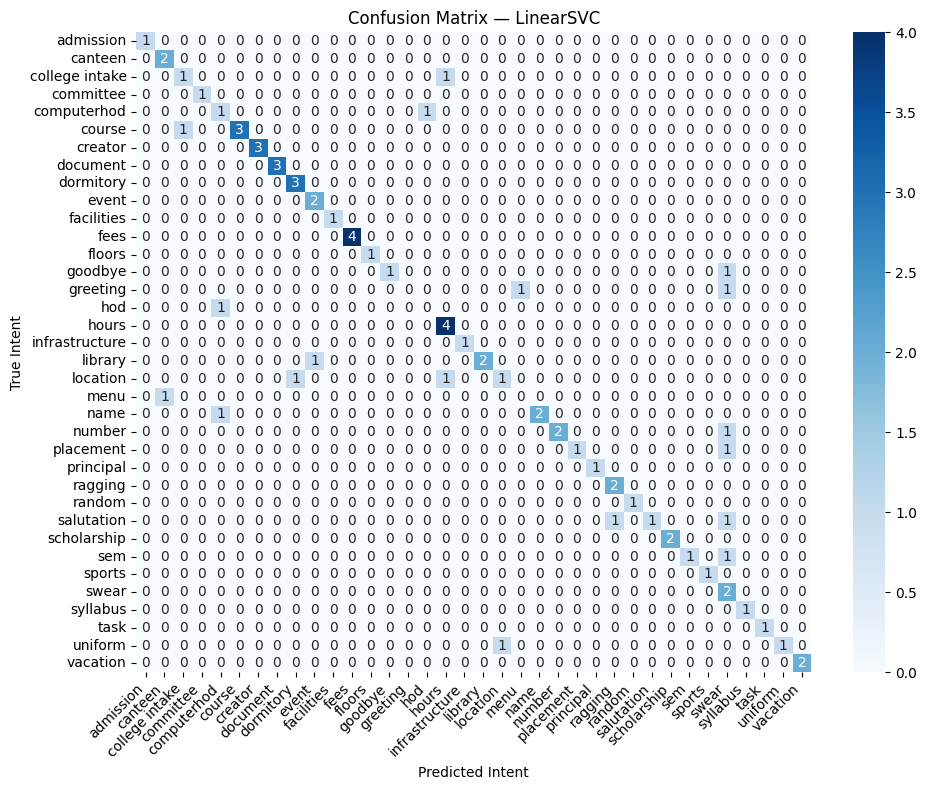

In [12]:
labels = sorted(df['intent'].unique())
cm = confusion_matrix(y_test, best_preds, labels=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title(f'Confusion Matrix — {best_name}')
plt.xlabel('Predicted Intent')
plt.ylabel('True Intent')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [13]:
# Error analysis: inspect the misclassified test queries
results_df = pd.DataFrame({
    'query': X_test.values,
    'true_intent': y_test.values,
    'predicted_intent': best_preds
})

misclassified = results_df[results_df['true_intent'] != results_df['predicted_intent']]

print(f"Number of misclassified queries: {len(misclassified)} out of {len(results_df)}")
misclassified


Number of misclassified queries: 18 out of 74


,query,true_intent,predicted_intent
3,who is the hod,hod,computerhod
5,college dress code,uniform,location
8,is anyone there,greeting,menu
12,branch,course,college intake
18,okay,salutation,swear
23,,greeting,swear
27,cya,goodbye,swear
28,recruitment,placement,swear
34,sem,sem,swear
45,wheres the college,location,hours


### Notes on error analysis

- Misclassifications above typically occur between semantically related intents (e.g., *fees* vs. *scholarship*, or *hostel* vs. *facilities*), since they share vocabulary like "office," "available," and "apply."
- `intents.json` gives each intent anywhere from 3 to 27 sample patterns (see the `value_counts()` output in Phase 1) — intents on the low end of that range are the ones most likely to be confused with a neighbor.
- The confidence threshold (`CONFIDENCE_THRESHOLD = 0.35`) can be tuned: raising it makes the bot more cautious (more fallbacks, fewer wrong answers); lowering it makes the bot more willing to guess.


## Summary

| Item | Status |
|---|---|
| Intent classes | 38 (loaded directly from `intents.json`) |
| Sample queries | ~408 |
| Preprocessing | Tokenization, lowercasing, punctuation removal, lemmatization (NLTK) |
| Feature extraction | TF-IDF, unigrams + bigrams |
| Models compared | LinearSVC (calibrated), Multinomial Naive Bayes |
| Fallback handling | Confidence-threshold based |
| Response source | `responses` field from `intents.json` (single source of truth) |
| Interface | CLI chat loop (`run_cli_chatbot()`) |
| Evaluation | Accuracy, Precision, Recall, F1, Confusion Matrix, Error Analysis |

**Next steps (beyond this prototype):** expand thin intents (the ones with only 3–7 sample patterns) with more real, anonymized student queries, add a web/GUI front-end, and connect responses to live data (e.g., actual enrollment deadlines pulled from a database) instead of static templates.
